# Network Interdiction Analysis

Sections, in order: flow reduction of every method per graph family, a
head-to-head table (simulated annealing + greedy repair against greedy from
scratch), Gurobi's best incumbent over time against where every other method
finishes (one row, then all rows), a performance-distribution plot (final solution quality per
family and method), raw-annealer feasibility against problem size, a check of
this rerun against the values on the D-Wave slides, the exact penalty windows
λ with the one instance where no λ exists, how close simulated annealing
gets to the QUBO ground state, and the penalty QAOA on the tiny instances.
All figures before the QAOA section use `results/slide_instances_sa.csv`,
the classical rerun of the nine instances behind slides 8–10 of
`S-T_NIP.pptx` (the original D-Wave result files were not stored). The
D-Wave (QA) column is empty because D-Wave runs are paused. The QAOA
section reads `results/qaoa_tiny.csv` (written by `run_qaoa_benchmark.py`)
and `results/sample_results_sa.csv`, the classical results for the same rows.

In [1]:
from pathlib import Path
import sys
import importlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    from IPython.display import display
except ImportError:  # executed outside Jupyter
    display = print

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "utils.py").exists():
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import utils
utils = importlib.reload(utils)

apply_plot_style = utils.apply_plot_style
read_provenance = utils.read_provenance
load_results = utils.load_results
head_to_head_table = utils.head_to_head_table
compare_with_slides = utils.compare_with_slides
plot_ratio_by_family = utils.plot_ratio_by_family
plot_performance_distribution = utils.plot_performance_distribution
plot_raw_sa_feasibility = utils.plot_raw_sa_feasibility
plot_slide_check = utils.plot_slide_check
plot_lambda_windows = utils.plot_lambda_windows
plot_flow_curve = utils.plot_flow_curve
plot_energy_gap = utils.plot_energy_gap
plot_incumbent_trajectory = utils.plot_incumbent_trajectory
plot_time_vs_quality = utils.plot_time_vs_quality
time_summary = utils.time_summary
load_qaoa_results = utils.load_qaoa_results
qaoa_vs_classical_table = utils.qaoa_vs_classical_table
plot_qaoa_depth = utils.plot_qaoa_depth
plot_qaoa_transfer = utils.plot_qaoa_transfer

apply_plot_style()

RESULTS_CSV = REPO_ROOT / "results" / "slide_instances_sa.csv"
FIGURES_DIR = REPO_ROOT / "figures"
FIGURES_DIR.mkdir(exist_ok=True)

# Row for the single-row incumbent trajectory: a k-NN row where greedy from
# scratch is not optimal, so every method's position is visible.
TRAJ_INSTANCE = "100_6.2dnnflow"
TRAJ_BUDGET = 6

# Instance and budget whose penalty window is empty (section "Penalty Windows").
EMPTY_WINDOW_INSTANCE = "90_0.1.erdosflow"
EMPTY_WINDOW_BUDGET = 10

# QAOA section: run_qaoa_benchmark.py's rows and the classical results for the
# same six tiny rows; the comparison table shows QAOA at this depth.
QAOA_CSV = REPO_ROOT / "results" / "qaoa_tiny.csv"
SAMPLE_CSV = REPO_ROOT / "results" / "sample_results_sa.csv"
QAOA_TABLE_DEPTH = 3

df = load_results(RESULTS_CSV)

print(f"Loaded {len(df)} rows from {RESULTS_CSV.relative_to(REPO_ROOT)}")
print(f"Families: {', '.join(f'{f} ({int((df.family == f).sum())})' for f in utils.FAMILY_ORDER)}")
for line in read_provenance(RESULTS_CSV):
    print(f"  {line}")
utils_path = Path(utils.__file__).resolve().relative_to(REPO_ROOT)
print(f"Loaded utils from: {utils_path}")


%load_ext autoreload
%autoreload 2

Loaded 27 rows from results/slide_instances_sa.csv
Families: planar (9), Erdős–Rényi (9), k-NN (9)
  Generated by run_benchmark.py -- see README, "Regenerating the results CSV".
  repo commit: 9b7b329a176b36db17382c9a776cdb0a8c7ca237
  generated (UTC): 2026-10-01T13:35:36+00:00
  exact backend: gurobi
  solver passes: sa
  baselines: greedy, random (seed 0)
  simulated annealing seed: 0
  Gurobi trajectory solve threads: 1
  lambda = auto: the midpoint of the exact window (lambda_lo, lambda_hi); see the run_benchmark.py docstring.
  empty lambda window (f not convex at B), baselines only: testcases/90_0.1.erdosflow B=10
  qa columns are empty: that pass was not run here. Re-run with --solvers to fill them.
Loaded utils from: utils.py


## Flow Reduction by Family

For every instance and budget B on the slides, **`plot_ratio_by_family`**
scores each method by the flow reduction it achieves as a fraction of the
optimal reduction (1.0 = optimal, computed by Gurobi):

- **SA (raw sample)** — the best budget-feasible sample among simulated
  annealing's 20 lowest-energy samples;
- **SA + greedy repair** — the best of those 20 samples after greedy repair to
  exactly B cuts;
- **Greedy from scratch** — cut the single most harmful arc, B times, starting
  from nothing;
- **Random start + repair** — 20 random starts (each arc cut with probability
  B/E) after the same repair, i.e. samples that know the budget and nothing
  else.

Lines join the budgets of one instance; the grey number under each group is
its QUBO size, the slides' x-axis label. Vermillion crosses mark rows where raw
SA had no budget-feasible sample, and "no valid λ" marks the one row whose
penalty window is empty (see **Penalty Windows** below), which therefore has
no SA result.

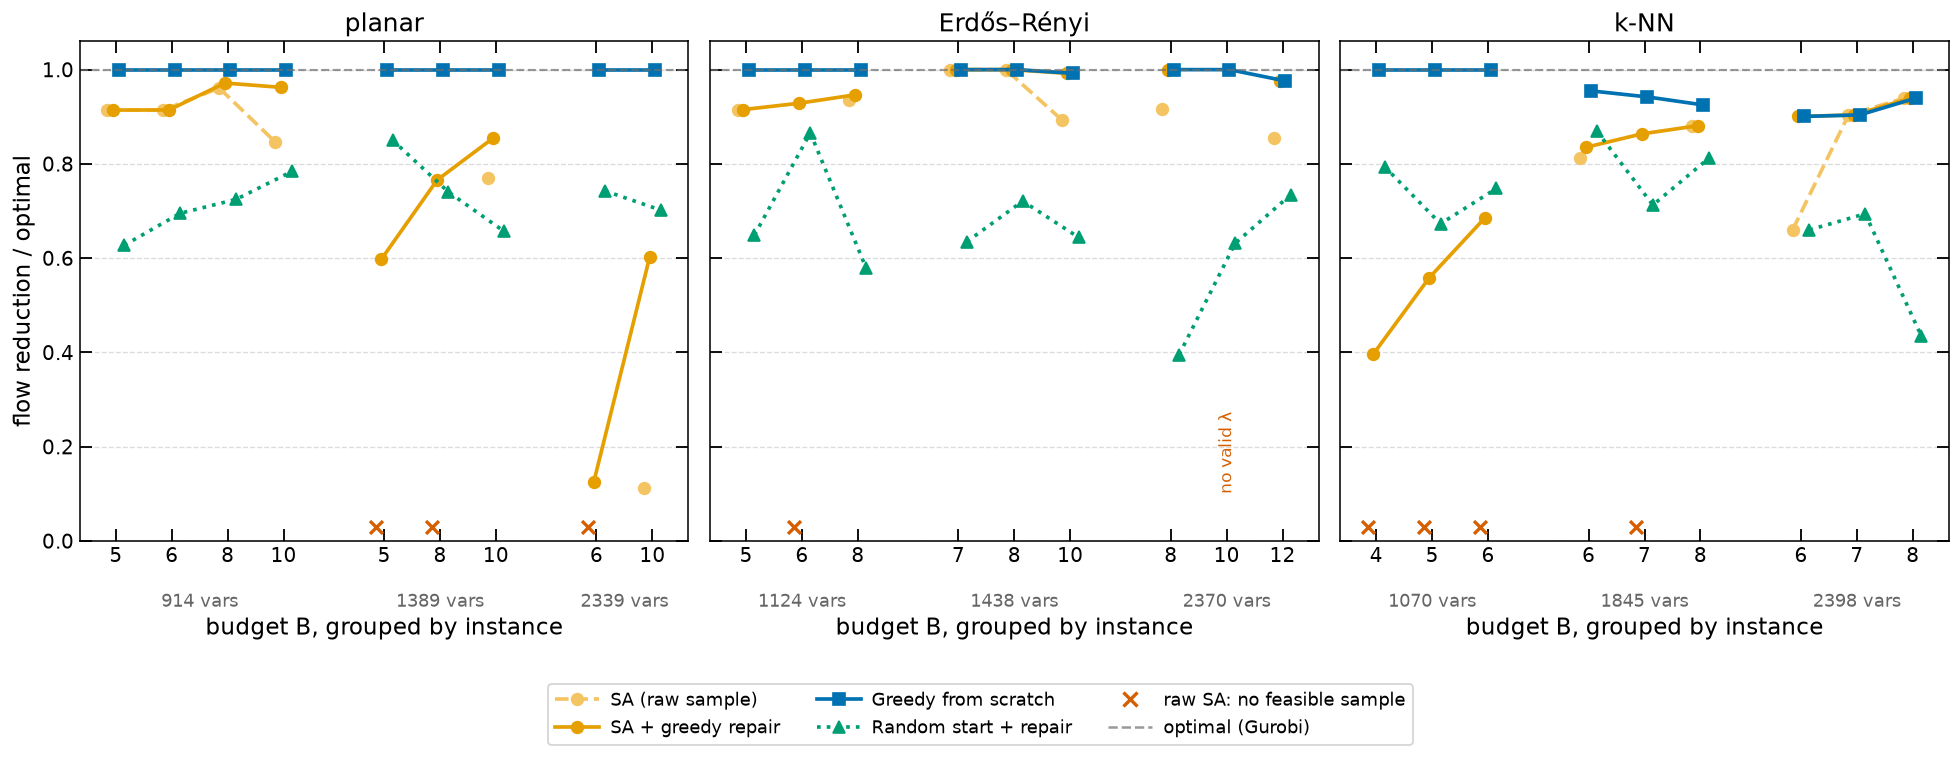

In [2]:
fig_ratio = plot_ratio_by_family(df)
plt.savefig(FIGURES_DIR / "ratio_by_family.png", dpi=150, bbox_inches="tight")
plt.show()

### Head-to-head: SA + repair against greedy from scratch

**`head_to_head_table`** counts, per family, the rows where each of the two
leaves less flow (rows without a QUBO excluded). The headline is the
`SA+repair better` column: greedy from scratch is never beaten, and it is
optimal on every planar row. Greedy leaves gaps on two Erdős–Rényi rows
and on six k-NN rows. The k-NN gaps are larger and more frequent, making
that family the stronger test for a better method.

In [3]:
summary = head_to_head_table(df)
display(summary.round(3))
print(f"Greedy from scratch is optimal on {int((df['Greedy'] == df['Opt_NIP']).sum())} "
      f"of {len(df)} rows (including the empty-window row).")

,rows,SA+repair better,tie,Greedy better,Greedy optimal,SA+repair optimal,raw SA feasible,mean ratio SA+repair,mean ratio Greedy
planar,9,0,0,9,9,0,6,0.745,1.000
Erdős–Rényi,8,0,5,3,6,3,7,0.970,0.996
k-NN,9,0,3,6,3,0,5,0.774,0.952
all,26,0,8,18,18,3,18,0.824,0.982


Greedy from scratch is optimal on 19 of 27 rows (including the empty-window row).


## Gurobi Incumbent Trajectory

The plots above score every method only by its final answer. Here time is on
the x-axis. During each Gurobi solve a **MIPSOL callback** records every new
incumbent (the same callback as `qp_gurobi/solve.py` in the
quantum-preconditioning repository), and each incumbent is scored the same
way as the other methods: by the max flow that survives its cuts.
**`plot_incumbent_trajectory`** shows one row (`TRAJ_INSTANCE`,
`TRAJ_BUDGET`): Gurobi's best incumbent so far as black steps, with a dotted
line where Gurobi proves optimality, against the point where each other
method finishes.

The times are comparable: all exclude building the model or QUBO, as
Gurobi's `Runtime` does, and Gurobi is limited to one thread
(`--gurobi-threads 1`), the same as simulated annealing and greedy. SA's raw
sample is placed at the end of sampling; SA + repair adds the time to decode
and repair its 20 best samples.

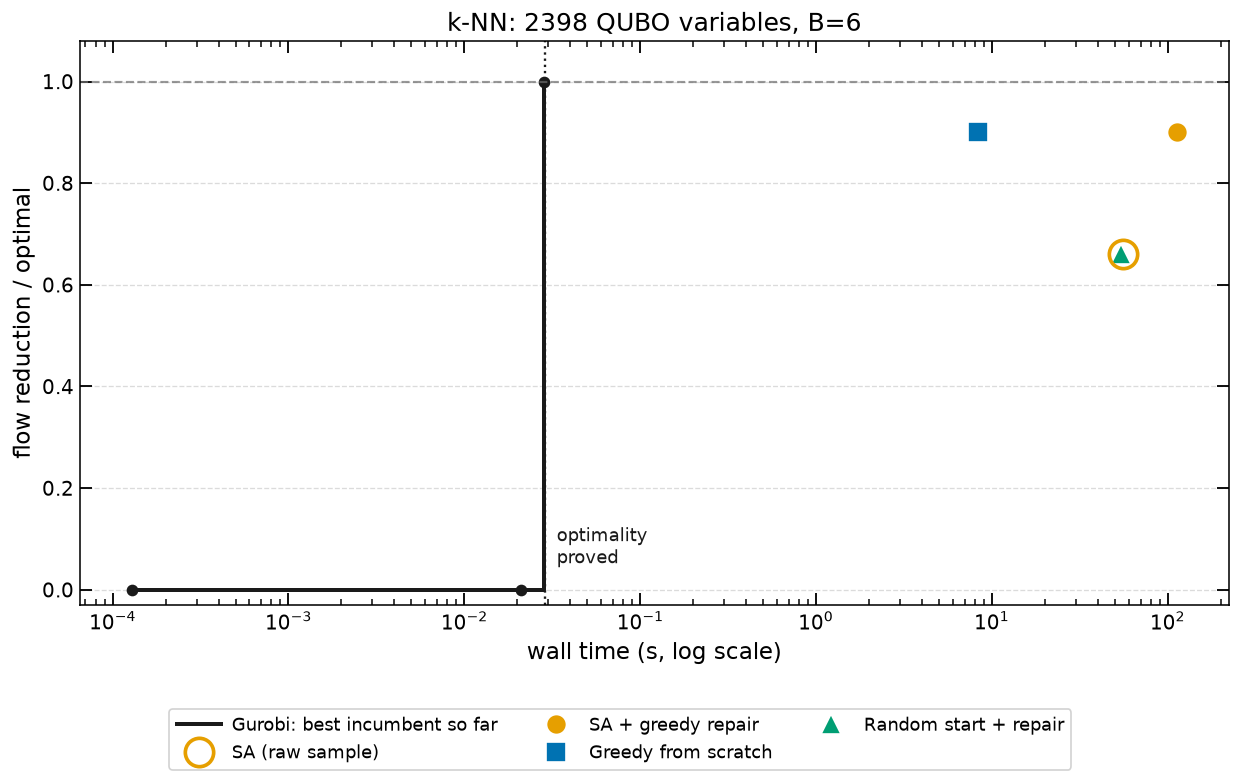

In [4]:
fig_traj = plot_incumbent_trajectory(df, TRAJ_INSTANCE, TRAJ_BUDGET)
plt.savefig(FIGURES_DIR / "gurobi_trajectory.png", dpi=150, bbox_inches="tight")
plt.show()

### Time vs quality, all rows

**`plot_time_vs_quality`** repeats the comparison for every row: each method's
wall time against its flow reduction. Gurobi sits at 1.0, plotted at the time
of its first optimal incumbent. **`time_summary`** gives the medians.

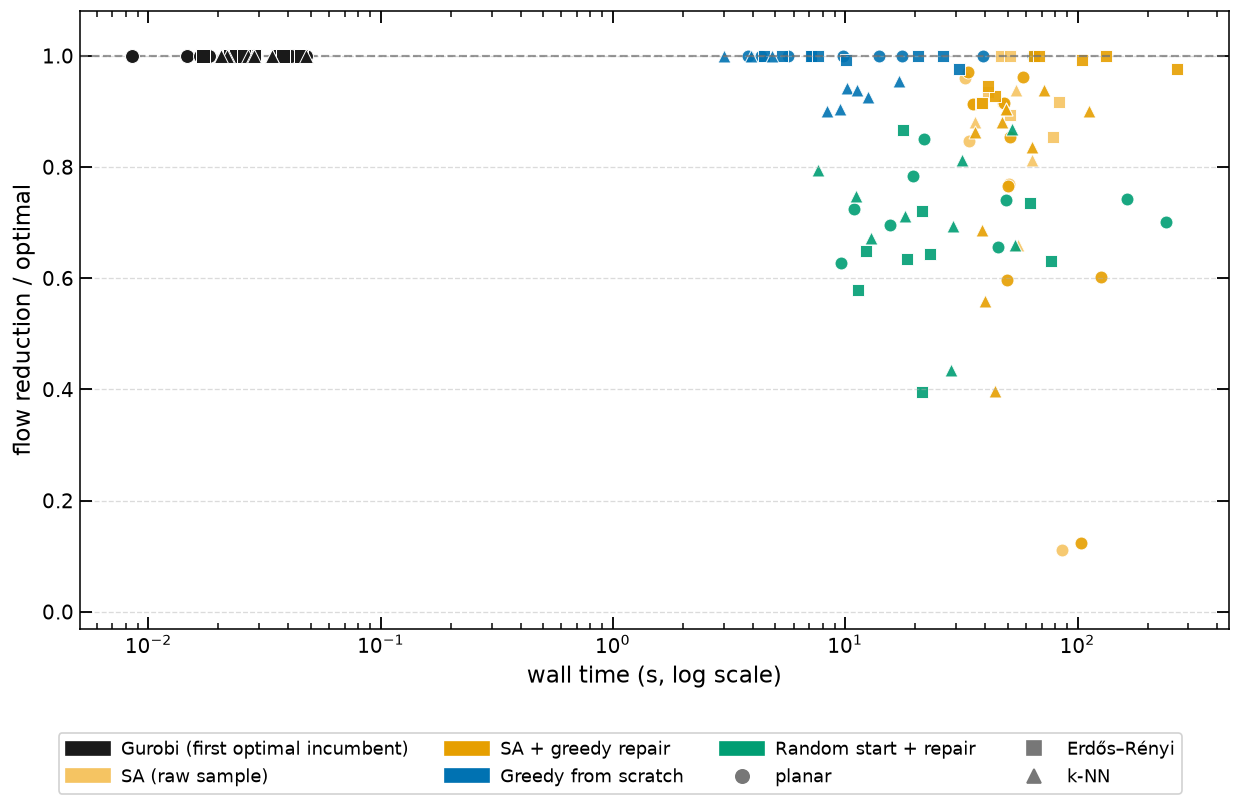

,median time (s),median ratio,rows
Gurobi (optimal incumbent),0.0257,1.0000,27.0
Gurobi (optimality proved),0.0260,1.0000,27.0
SA (raw sample),48.5468,0.9091,26.0
SA + greedy repair,49.9782,0.9091,26.0
Greedy from scratch,9.4823,1.0000,27.0
Random start + repair,21.4553,0.7020,27.0


In [5]:
fig_time = plot_time_vs_quality(df)
plt.savefig(FIGURES_DIR / "time_vs_quality.png", dpi=150, bbox_inches="tight")
plt.show()
display(time_summary(df).round(4))

## Performance Distribution

**`plot_performance_distribution`** reports final solution *quality* rather
than per-row detail: `performance % = 100 × ratio`, where 100% means the method
matched Gurobi's optimum. The top strip holds the rows each method solved
exactly, with the fraction above each column; the log-scale main panel shows
how far short the remaining rows fell, with a black bar at each method's mean.
SA + repair beats random starts with the same repair in most rows — so SA's
samples do carry information about the instance — but both trail greedy from
scratch: greedy repair can add or remove cuts until there are B of them, but
it cannot swap out a wrong cut, so starting from an SA sample anchors it to
that sample's mistakes.

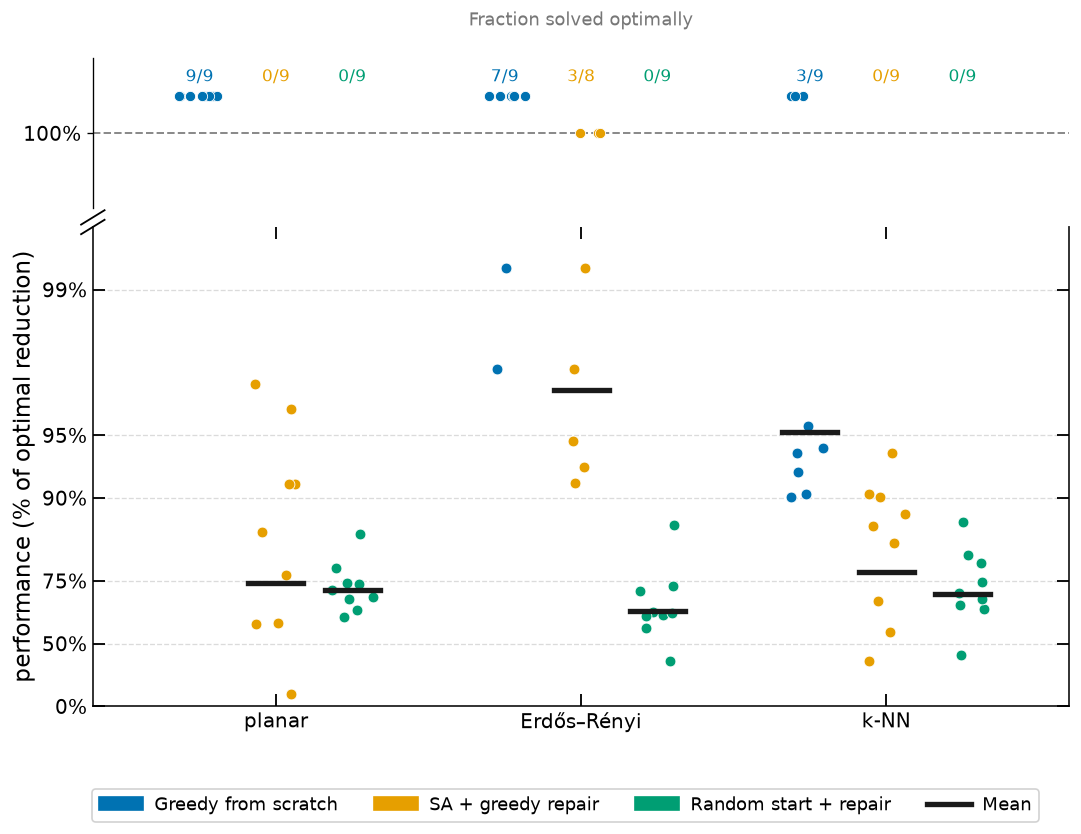

In [6]:
fig_perf = plot_performance_distribution(df)
plt.savefig(FIGURES_DIR / "performance_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## Raw Annealer Feasibility vs Problem Size

The QUBO enforces the budget only through a linear penalty, so a low-energy
sample can cut more or fewer arcs than B. **`plot_raw_sa_feasibility`** shows
the quality of raw SA on rows where at least one of its 20 best samples
respected the budget; the vermillion number above a size counts the rows where
none did.

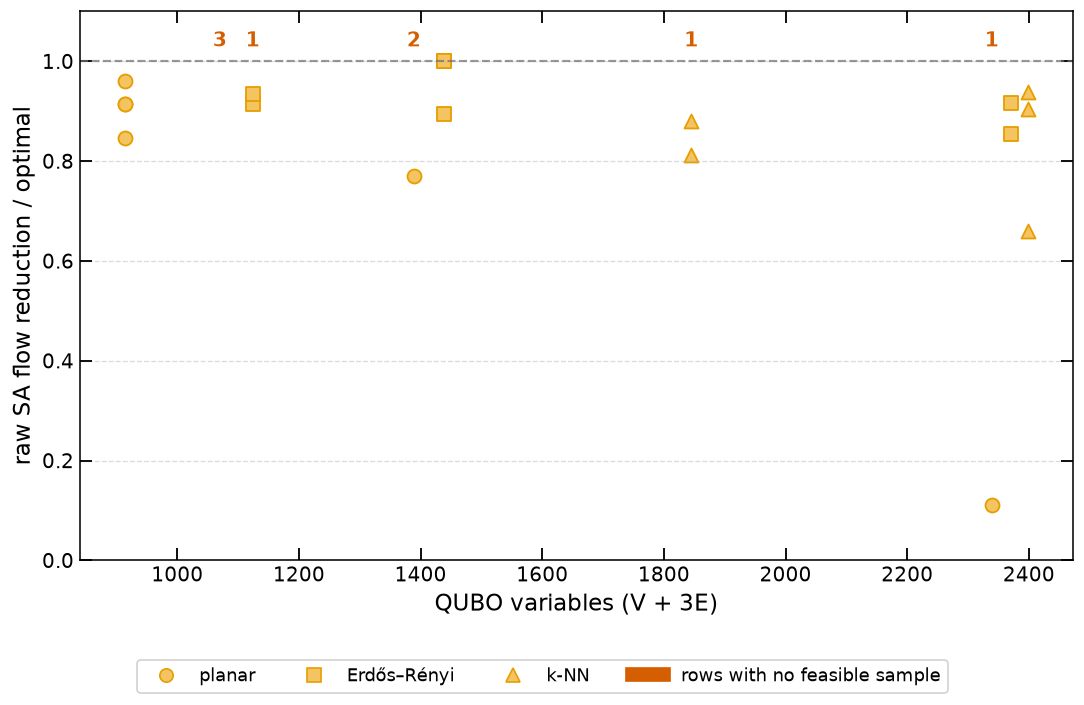

In [7]:
fig_feas = plot_raw_sa_feasibility(df)
plt.savefig(FIGURES_DIR / "raw_sa_feasibility.png", dpi=150, bbox_inches="tight")
plt.show()

## Reproducing the Slides

The slides' numbers survive only as figures, so **`compare_with_slides`**
joins this rerun with values read off slides 8–10 by eye (about ±0.01; pinned
in `utils.slide_values`). **`plot_slide_check`** puts the slides'
repaired "QA/SA-Greedy" values against this rerun's greedy from scratch
(left) and SA + repair (right). Points inside the shaded ±0.01 band agree to
reading precision.

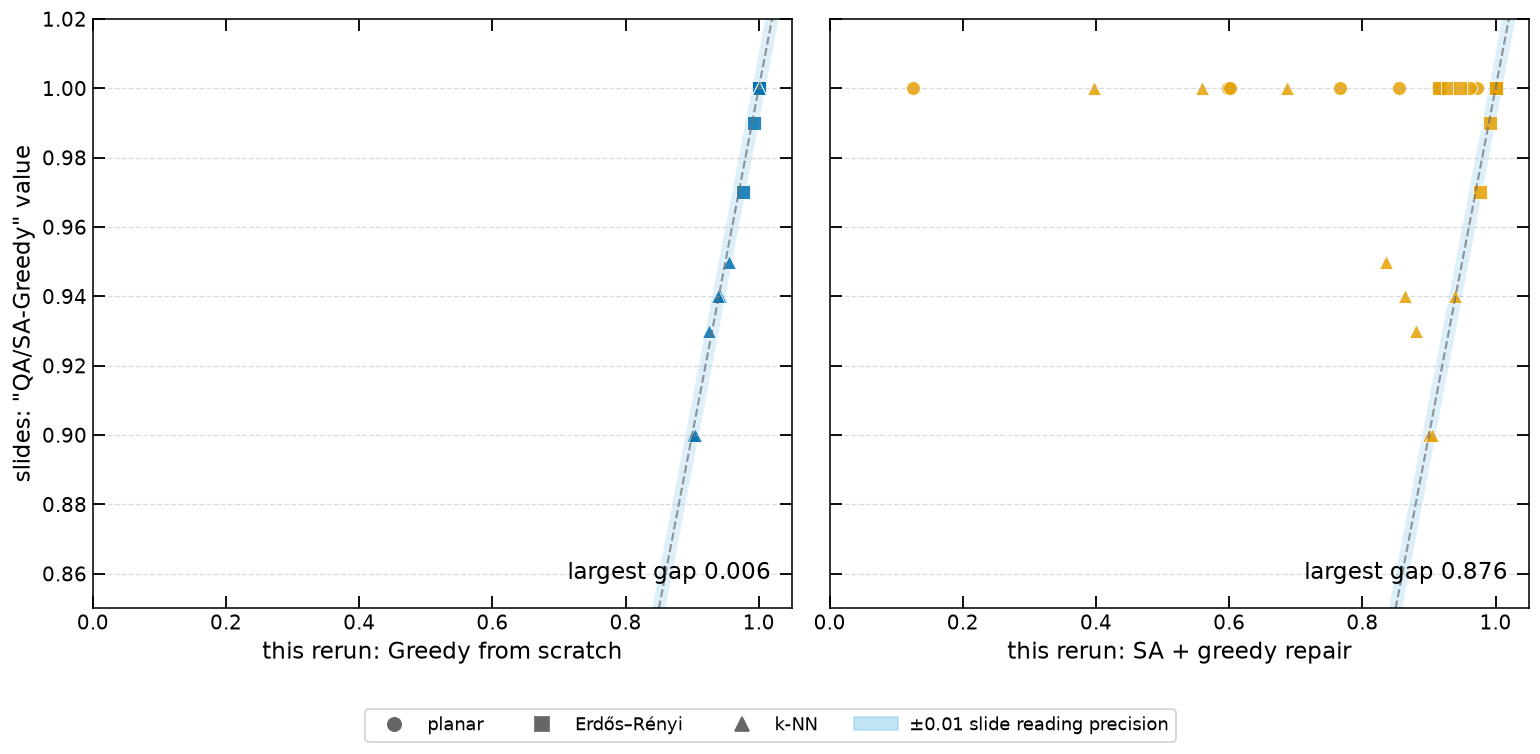

Largest gap, slides vs greedy from scratch: 0.006
Largest gap, slides vs SA + repair:         0.876
Median gap in raw SA (rows feasible in both): 0.004


In [8]:
cmp = compare_with_slides(df)
fig_slides = plot_slide_check(cmp)
plt.savefig(FIGURES_DIR / "slide_check.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Largest gap, slides vs greedy from scratch: {cmp['gap_vs_greedy'].max():.3f}")
print(f"Largest gap, slides vs SA + repair:         {cmp['gap_vs_sa_repair'].max():.3f}")
print(f"Median gap in raw SA (rows feasible in both): {cmp['gap_raw_sa'].median():.3f}")

### Why do the slides' repaired values match greedy from scratch?

Every one of the 27 repaired values on the slides lies within reading precision
of *greedy from scratch*, and far from this rerun's SA + repair. The cause is
the bug fixed in issue #12: before that fix, `improve_dwave_solution()` looked
samples up by integer index, while PyQUBO keys them `'x_0'`, `'x_1'`, …, so it
never saw a cut and always repaired from an empty solution — which *is* greedy
from scratch. It is also why the slides' QA-Greedy and SA-Greedy bars were
identical on every row. The raw QA and SA bars were real samples and are not
affected by that repair bug. The original penalty values were not recovered,
and this rerun uses exact-window midpoints instead of the slides' SA-based
bisection. Randomness and unrecorded or changed penalty choices prevent
isolating the cause of the raw-SA differences (the median gap is printed
above). The practical consequence is that the slides' "greedy post-processing
recovers optimal solutions" result describes the greedy heuristic, not the
annealer.

## Penalty Windows

The budget term in the QUBO is linear, λ·(Σx − B), so its ground state is the
optimal B-cut interdiction only for λ inside an exact window,

$$\max_{k>B}\frac{f(B)-f(k)}{k-B} \;<\; \lambda \;<\; \min_{k<B}\frac{f(k)-f(B)}{B-k},$$

where f(k) is the best surviving flow with k cuts. `run_benchmark.py`
computes the window with Gurobi and uses its midpoint.
**`plot_lambda_windows`** shows every window and the λ used. Many are only a
few units wide, which is why hand-tuned λ was fragile; one is empty.

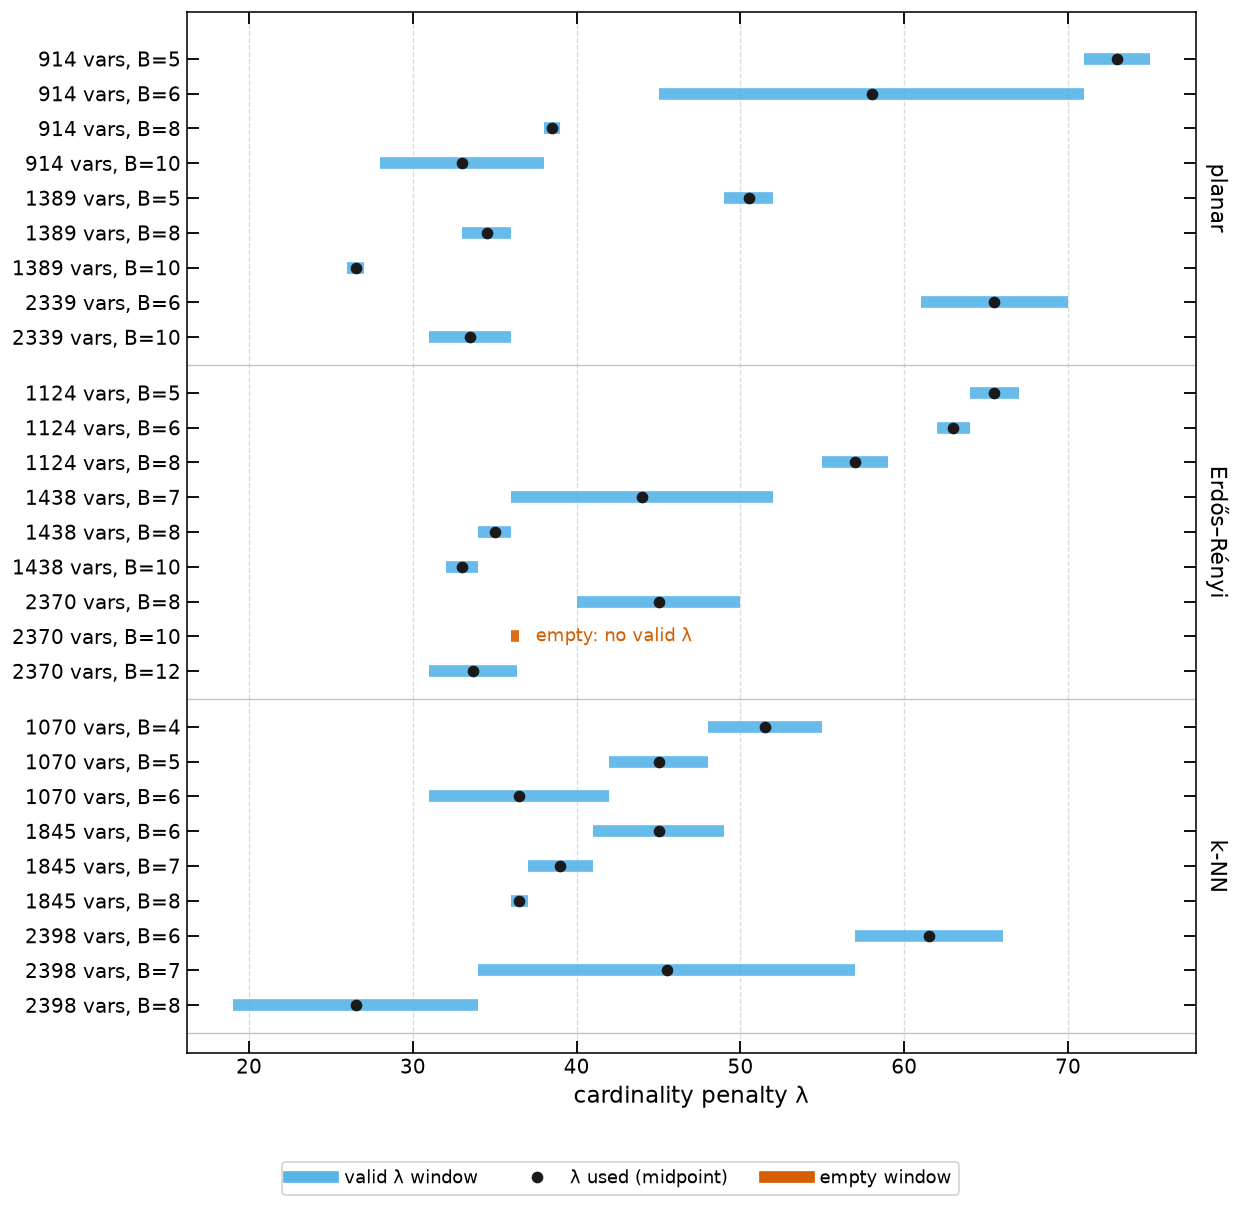

Non-empty windows: 26 of 27; median width 5.17; 6 are 2 or narrower.


In [9]:
fig_lambda = plot_lambda_windows(df)
plt.savefig(FIGURES_DIR / "lambda_windows.png", dpi=150, bbox_inches="tight")
plt.show()

nonempty = df[df["lambda_width"] > 0]
print(f"Non-empty windows: {len(nonempty)} of {len(df)}; median width "
      f"{nonempty['lambda_width'].median():.2f}; "
      f"{int((nonempty['lambda_width'] <= 2).sum())} are 2 or narrower.")

### Why is one window empty?

A strict window is empty when its lower end is at least its upper end.
Equal ends mean that other cut counts tie at the only candidate λ; this can
happen even for a convex curve, such as f = [10, 5, 0] at B = 1. When the
lower end is larger, B lies above the lower convex envelope.

The slide row is the latter case: the B-th cut saves less than the average
of the next few, so a per-cut price cannot make exactly B cuts optimal.
**`plot_flow_curve`** draws f(k) with its lower convex envelope; the budget
sits above it. This cell recomputes f with Gurobi, so it needs a full Gurobi
license and is skipped otherwise.

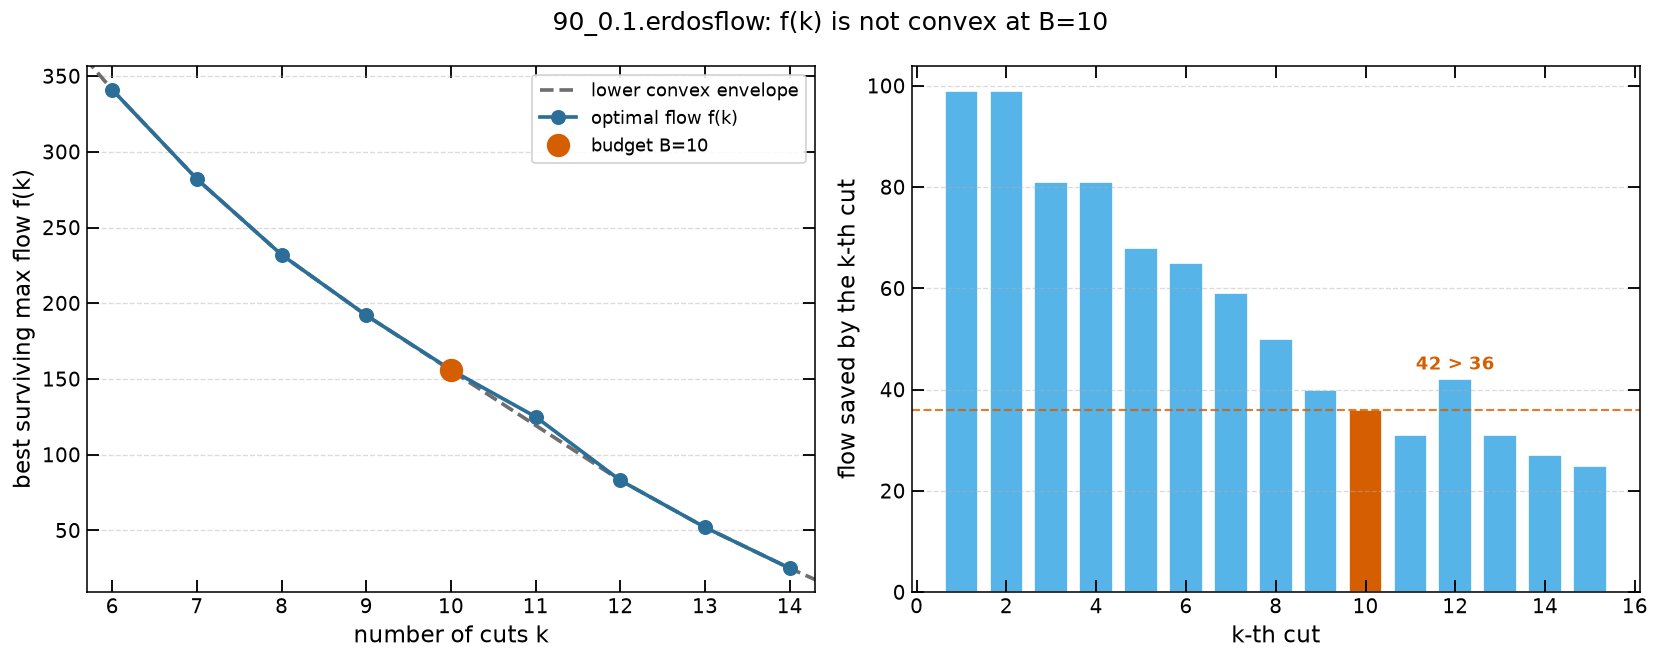

saving of the k-th cut: {8: 50, 9: 40, 10: 36, 11: 31, 12: 42, 13: 31}
window at B: (36.5, 36.0)


In [10]:
import contextlib
import io

try:
    import network_interdiction as ni
    import run_benchmark as rb

    _g, _s, _t = ni.read_flow_file(str(REPO_ROOT / "testcases" / EMPTY_WINDOW_INSTANCE))
    with contextlib.redirect_stdout(io.StringIO()):  # solve_nip_gurobi prints every solve
        flow_curve = rb.optimum_curve("gurobi", _g, _s, _t, EMPTY_WINDOW_BUDGET)
    fig_curve = plot_flow_curve(
        flow_curve, EMPTY_WINDOW_BUDGET,
        title=f"{EMPTY_WINDOW_INSTANCE}: f(k) is not convex at B={EMPTY_WINDOW_BUDGET}")
    plt.savefig(FIGURES_DIR / "flow_curve_empty_window.png", dpi=150, bbox_inches="tight")
    plt.show()
    _ks = range(EMPTY_WINDOW_BUDGET - 2, EMPTY_WINDOW_BUDGET + 4)
    print("saving of the k-th cut:",
          {k: flow_curve[k - 1] - flow_curve[k] for k in _ks})
    print("window at B:", rb.lambda_window(flow_curve, EMPTY_WINDOW_BUDGET))
except Exception as e:  # no (full) Gurobi license
    print(f"Skipped: needs a full Gurobi license ({type(e).__name__}: {e})")

## QUBO Energy Gap

**`plot_energy_gap`** measures how close simulated annealing gets to the QUBO
ground state, as the relative gap `1 − E(SA) / E(ground state)` (energies are
negative, so 0 means SA reached the ground state; those rows are counted in
vermillion at the bottom).

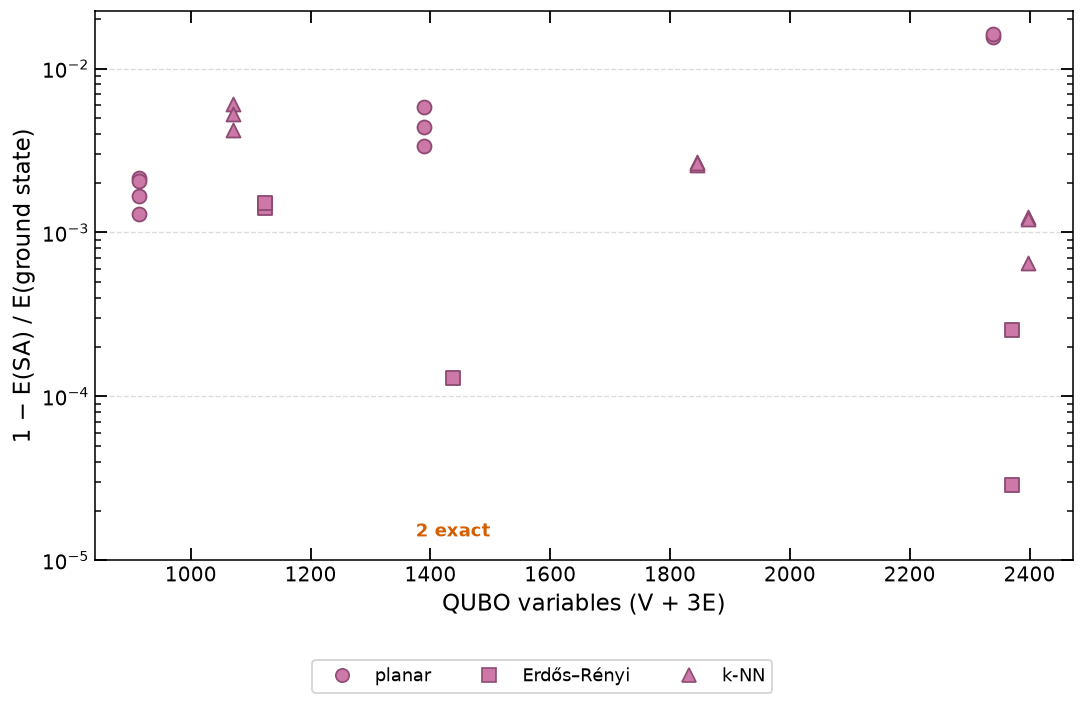

SA reached the exact ground-state energy on 2 of 26 rows.


In [11]:
fig_energy = plot_energy_gap(df)
plt.savefig(FIGURES_DIR / "energy_gap.png", dpi=150, bbox_inches="tight")
plt.show()
_e = df.dropna(subset=["SA_QUBO"])
print(f"SA reached the exact ground-state energy on "
      f"{int(np.isclose(_e['SA_QUBO'], _e['Opt_QUBO']).sum())} of {len(_e)} rows.")

## QAOA on the Tiny Instances

The penalty QAOA (`qaoa_qiskit.py` and `qaoa_cudaq.py`, issues #3 and #16)
solves the same QUBO as the annealer, one qubit per QUBO variable, on a
statevector simulator, so only the `tiny_*` instances fit (14–22 qubits).
`run_qaoa_benchmark.py` trained depths p = 1, 2 and 3 on the six instance and
budget rows of `results/sample_results_sa.csv`, with λ from its exact window,
on Qiskit Aer. The CUDA-Q backend prepares the same state for the same angles;
`tests/test_qaoa.py` checks both against a numpy simulation. There are two
kinds of score:

- **exact**, from the trained state's probabilities: the approximation ratio
  (E_max − ⟨H⟩)/(E_max − E_min), and P(optimal), the probability that one
  measurement is an optimal interdiction (at most B cuts, leaving the optimal
  flow);
- **from 4096 shots**, decoded and repaired the way the annealer's 20 best
  samples are.

**`qaoa_vs_classical_table`** puts the surviving flows (lower is better) of
greedy, SA and QAOA at p = `QAOA_TABLE_DEPTH` side by side. Every method
reaches the optimum on all six rows, raw QAOA shots included, so on instances
this small the flows cannot separate QAOA from greedy. The informative columns
are the last two: one measurement of the trained state is an optimal
interdiction 1.6 to 8.5 times as often as a uniformly random bit string.

In [12]:
qaoa = load_qaoa_results(QAOA_CSV)
sample = pd.read_csv(SAMPLE_CSV, comment="#")
depths = ", ".join(str(reps) for reps in sorted(qaoa["reps"].unique()))
print(f"Loaded {len(qaoa)} rows from {QAOA_CSV.relative_to(REPO_ROOT)}: "
      f"{qaoa['case'].nunique()} cases at depths {depths}")
for line in read_provenance(QAOA_CSV):
    print(f"  {line}")
qaoa_table = qaoa_vs_classical_table(qaoa, sample, QAOA_TABLE_DEPTH)
display(qaoa_table.round(3))

Loaded 18 rows from results/qaoa_tiny.csv: 6 cases at depths 1, 2, 3
  Generated by run_qaoa_benchmark.py -- see its docstring.
  repo commit: 9c8eeb69d7500339843375605d2099c87b5eb124
  generated (UTC): 2026-10-07T16:40:25+00:00
  backend: qiskit (qiskit 2.4.2, qiskit-aer 0.17.2)
  depths: 1, 2, 3; shots: 4096; seed: 0; COBYLA maxiter: 300, from the linear-ramp start only
  lambda = auto: the midpoint of the exact window, as in run_benchmark.py.
  transfer donor: testcases/tiny_a.flow B=1 (its angles at each depth, unchanged)


,qubits,optimum,greedy,SA raw,SA + repair,QAOA raw,QAOA + repair,"P(optimal), QAOA","P(optimal), uniform"
p = 3,,,,,,,,,
tiny_a B=1,14,5,5,5,5,5,5,0.322,0.125
tiny_b B=1,21,13,13,13,13,13,13,0.267,0.031
tiny_b B=2,21,5,5,5,5,5,5,0.120,0.062
tiny_c B=1,22,4,4,4,4,4,4,0.286,0.047
tiny_d B=1,21,13,13,13,13,13,13,0.212,0.031
tiny_d B=2,21,6,6,6,6,6,6,0.099,0.062


### Depth

**`plot_qaoa_depth`** follows each row over depth. The approximation ratio
(left) rises with p on every row, from 0.80–0.82 at p = 1 to 0.92–0.93 at
p = 3. P(optimal) relative to the uniform state (right) rises with it on the
B = 1 rows of the 21–22-qubit instances, to 6.1–8.5 at p = 3. On `tiny_a`
(14 qubits), where a random bit string is already optimal one time in eight,
it levels off near 2.6. On both B = 2 rows it stays between 1.6 and 2.1 at
every depth: the energy QAOA gains there does not go into better cuts. Which
terms it does lower is not measured here; the linear budget penalty (issue #2)
is the first suspect.

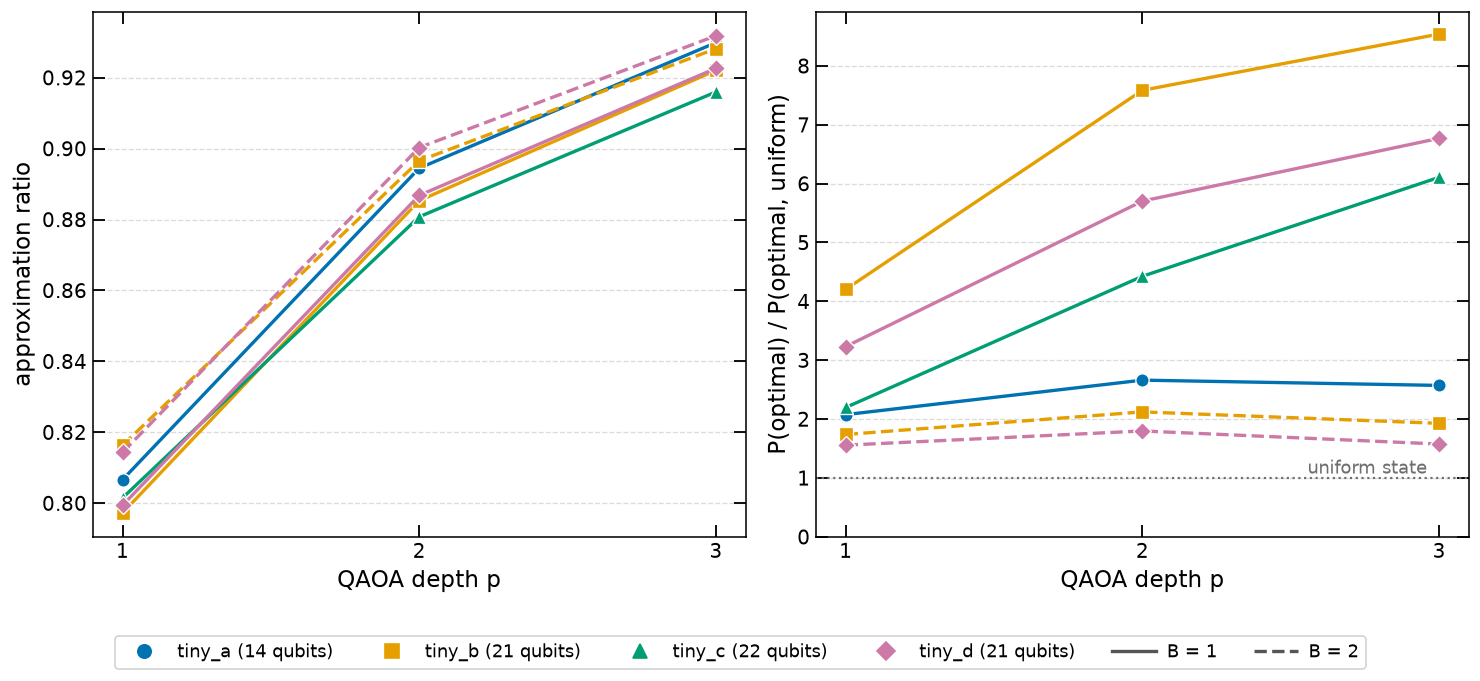

p = 1: approximation ratio 0.797–0.816; P(optimal) / uniform 1.56–4.20
p = 2: approximation ratio 0.881–0.900; P(optimal) / uniform 1.80–7.59
p = 3: approximation ratio 0.916–0.932; P(optimal) / uniform 1.58–8.54


In [13]:
fig_qaoa_depth = plot_qaoa_depth(qaoa)
plt.savefig(FIGURES_DIR / "qaoa_depth.png", dpi=150, bbox_inches="tight")
plt.show()
for reps, rows in qaoa.groupby("reps"):
    print(f"p = {reps}: approximation ratio {rows['approx_ratio'].min():.3f}–"
          f"{rows['approx_ratio'].max():.3f}; P(optimal) / uniform "
          f"{rows['enrichment'].min():.2f}–{rows['enrichment'].max():.2f}")

### Parameter Transfer Baseline

Issue #16 asks for QAOA angles trained on small instances to be reused on
larger ones. Before any learned model (a GAT, or the `TransferTrainer` of
IBM's `qaoa_training_pipeline`) comes the simplest version: take the angles
trained on `tiny_a` B = 1 (14 qubits) at each depth and use them unchanged on
every other row (21–22 qubits). The angles are comparable across instances
because `qaoa_common` scales every Hamiltonian to coefficients of at most 1.
**`plot_qaoa_transfer`** puts each row's score with its own trained angles (x)
against its score with the transferred ones (y). Every point sits on the
diagonal: the transferred approximation ratio is within 0.003 of the trained
one on every row and depth, and the transferred P(optimal) is 0.99–1.07 times
the trained one. On this family a learned transfer model has nothing to
improve; it has to be tested on instances that differ more (issue #1).

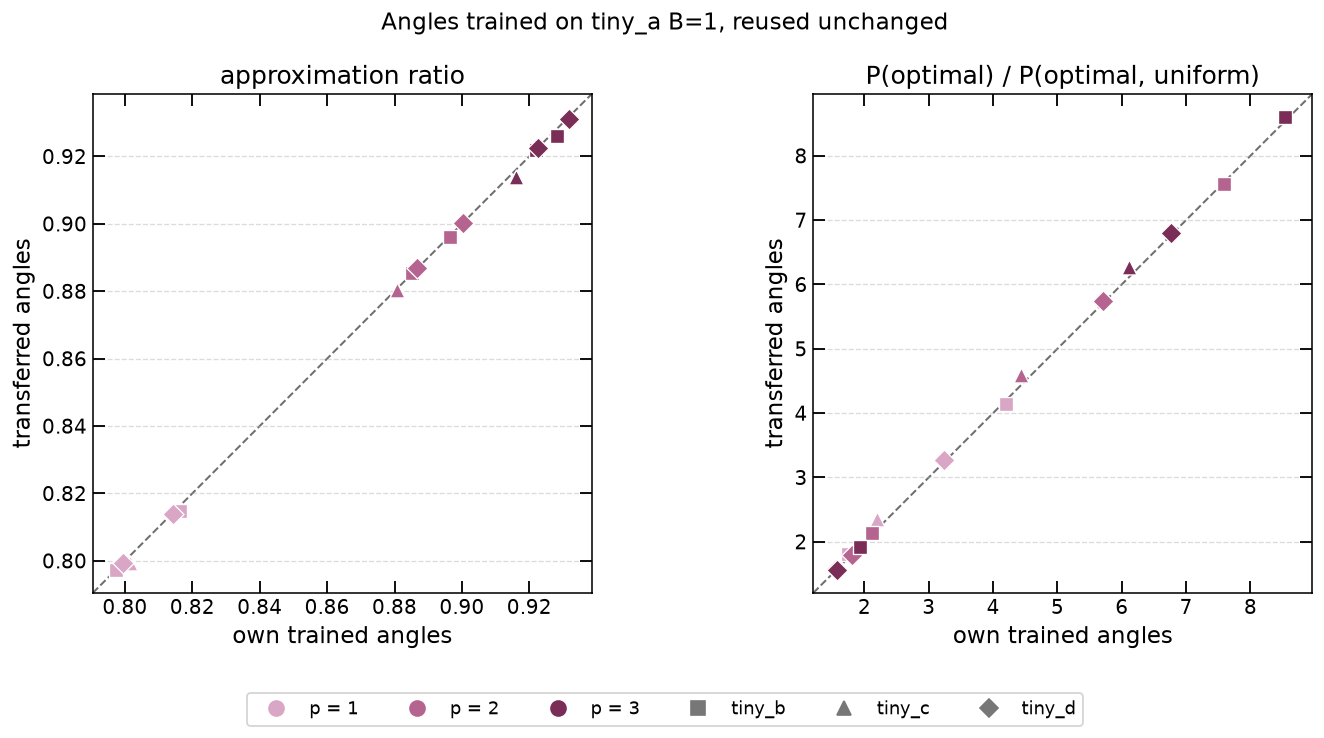

Transferred angles, 15 rows: approximation ratio at most 0.0023 below the trained one; P(optimal) 0.986–1.073 times the trained one.


In [14]:
fig_qaoa_transfer = plot_qaoa_transfer(qaoa)
plt.savefig(FIGURES_DIR / "qaoa_transfer.png", dpi=150, bbox_inches="tight")
plt.show()
_t = qaoa.dropna(subset=["transfer_p_optimal"])
_loss = _t["approx_ratio"] - _t["transfer_approx_ratio"]
_kept = _t["transfer_p_optimal"] / _t["p_optimal"]
print(f"Transferred angles, {len(_t)} rows: approximation ratio at most "
      f"{_loss.max():.4f} below the trained one; P(optimal) "
      f"{_kept.min():.3f}–{_kept.max():.3f} times the trained one.")